In [27]:
HEIGHT = 48
WIDTH = 36
FRAMES = 100
FPS = 12
MODE = 2 # 1 for sequence per frame, 2 for sequence per coordinate

In [28]:
!mkdir -p queries
!touch queries/.gitkeep
!rm queries/query_*.fa
from query_generator import generate_queries_by_frame, generate_queries_by_coordinate
if MODE == 1:
    generate_queries_by_frame(HEIGHT, WIDTH, FRAMES, FPS)
elif MODE == 2:
    generate_queries_by_coordinate(HEIGHT, WIDTH, FRAMES, FPS)

Done!                                                  


In [29]:
%%writefile custom.matrix
   A  C  G  T
A  2 -4  2 -4
C -4  2 -4  2
G  2 -4  2 -4
T -4  2 -4  2

Overwriting custom.matrix


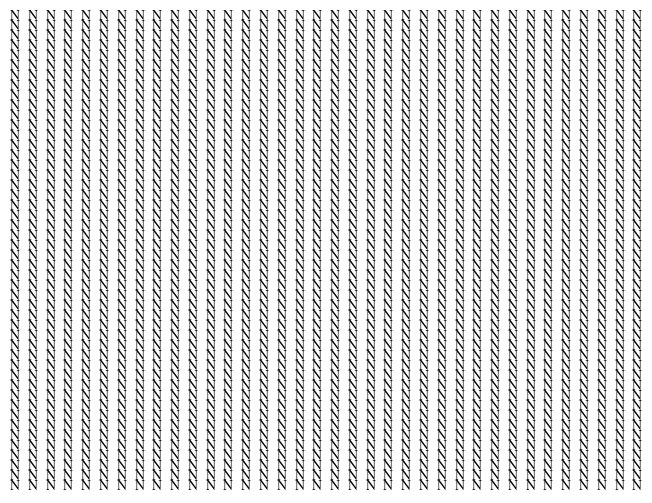

In [30]:
def get_sequence(data):
    if data["status"] != "Sequence found":
        return ""
    s = data["sequence"]
    if data["rev-comp"]:
        return s[::-1].replace("-", "").replace("A", "_").replace("T", "A").replace("_", "T").replace("C", "_").replace("G", "C").replace("_", "G")
    return s

sequences = {}

import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

plt.rcParams['font.family'] = 'STIXGeneral'

fig, ax = plt.subplots()
ax.axis("off")

fig_text = {}
for x in range(WIDTH):
    for y in range(HEIGHT):
        fig_text[(x, y)] = fig.text(x/WIDTH, 1-y/HEIGHT, "N")
        
def clear():
    for tx in fig_text.values():
        tx.set_text("-")
        tx.set_color((0,0,0))

def draw(i):
    if MODE == 1:
        if sequences[i] == "":
            return
        print(f"Drawing frame {i} in frame mode", end="\r", flush=True)
        remainder = len(sequences[i]) % WIDTH
        pad_width = (WIDTH - remainder) % WIDTH
        sequence = np.pad(np.array(list(sequences[i])), (0, pad_width), mode='constant', constant_values='-').reshape((-1, WIDTH))
        for x in range(WIDTH):
            for y in range(HEIGHT):
                base = sequence[y,x]
                color = (1,0,0) if base in "CT" else (0,0,1) if base in "AG" else (0,0,0)
                fig_text[(x, y)].set_text(base)
                fig_text[(x, y)].set_color(color)
    elif MODE == 2:
        print(f"Drawing frame {i} in coordinate mode", end="\r", flush=True)
        for x in range(WIDTH):
            for y in range(HEIGHT):
                sequence = sequences[(x, y)]
                if sequence != "":
                    base = sequence[i]
                    color = (1,0,0) if base in "CT" else (0,0,1)
                    fig_text[(x, y)].set_text(base)
                    fig_text[(x, y)].set_color(color)

In [31]:
# Sample
if MODE == 1:
    sample_frame = "3217"
    !glsearch36 -s custom.matrix -b 1 -d 1 queries/query_{sample_frame}.fa chr1.fna > sample.output

In [32]:
# Sample
if MODE == 1:
    from IPython.display import Image
    Image(filename=f'frames/frame{sample_frame.lstrip('0')}.png')

In [33]:
# Sample
if MODE == 1:
    with open(f"queries/query_{sample_frame}.fa", "r") as f:
        f.readline()
        sequences[-2] = f.readline()
    draw(-2)
    sequences.pop(-2)
    fig

In [34]:
if MODE == 1:
    clear()

In [35]:
# Sample
if MODE == 1:
    from output_parser import parse
    sequences[-1] = get_sequence(parse("sample.output"))
    draw(-1)
    sequences.pop(-1)
    fig

In [36]:
if MODE == 1:
    clear()

In [37]:
!mkdir -p outputs
!touch outputs/.gitkeep
!. align.sh

Aligning to queries/query_00_00.fa
Finished alignment in 112 seconds to outputs/fasta_00_00.output
Aligning to queries/query_00_01.fa
Finished alignment in 113 seconds to outputs/fasta_00_01.output
Aligning to queries/query_00_02.fa
^C
/bin/bash: line 1: kill: (90630) - No such process


In [38]:
from output_parser import parse_to_json_files
parse_to_json_files()

Parsing outputs/fasta_00_00.output
Parsing outputs/fasta_00_03.output
Parsing outputs/fasta_00_01.output
Parsing outputs/fasta_00_05.output
Parsing outputs/fasta_00_02.output
Parsing outputs/fasta_00_04.output
Sequences found: 0
Sequences not found: 6


In [39]:
import glob
import json

data = {}

if MODE == 1:
    i = 0
    for filename in glob.glob("outputs/fasta_*.json"):
        with open(filename, "r") as f:
            data[i] = json.loads(f.read())
        i += 1
elif MODE == 2:
    for x in range(WIDTH):
        for y in range(HEIGHT):
            with open(f"outputs/fasta_{y:02d}_{x:02d}.json", "r") as f:
                data[(x, y)] = json.loads(f.read())

print(len(data), "files loaded")

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/fasta_01_00.json'

In [ ]:
sequences = {}

if MODE == 1:
    for i in range(len(data)):
        sequences[i] = get_sequence(data[i])
elif MODE == 2:
    for x in range(WIDTH):
        for y in range(HEIGHT):
            sequences[(x, y)] = get_sequence(data[(x, y)])

print(sequences[0])

In [ ]:
ani = animation.FuncAnimation(fig=fig, func=draw, frames=len(sequences), interval=1)

FFwriter = animation.FFMpegWriter(fps=FPS)
ani.save('animation.mp4', writer=FFwriter)

In [ ]:
from IPython.display import Video
Video("animation.mp4")